# 🌐 Macro regime signals: credit, term structure, and inflation

## 🧭 tl;dr

Three macro ideas, each implemented with a **relative price ratio** because this project does not carry credit spreads, Treasury yields, or realised inflation:

| Rule | The idea | The proxy used here |
| --- | --- | --- |
| **Credit regime** | Credit spreads lead the business cycle and risk appetite (Gilchrist–Zakrajšek) | `HYG / IEF` price ratio versus its 200-day average |
| **Inflation rotation** | Inflation and deflation regimes reward different assets (Baltussen et al.) | Trend and momentum across `TIP`, `GLD`, `DBC`, falling back to `TLT` |
| **Term-structure tilt** | Curve slope predicts growth (Estrella–Mishkin) | `TLT / SHY` price ratio trend |

The headline result is uncomfortable for the idea: **every macro filter underperformed its own bare-momentum control in the recent period.** The credit filter was excellent during 2007–2014 and close to useless afterwards. A plain 200-day trend gate on SPY beat all three in 2022–2025.

<div style="border-left: 5px solid #2563EB; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #EFF6FF; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>Each rule is tested against the same rule <em>without</em> its macro filter. That is the only way to see whether the macro signal contributed anything. Ignore the equity curve and read the subperiod table first: a filter that worked in a crisis and failed everywhere else is a crisis instrument, not an allocation rule.</div>

## 📚 Sources and research question

- [Gilchrist & Zakrajšek (2012), *Credit spreads and business cycle fluctuations*](https://doi.org/10.1257/aer.102.4.1692) — the excess bond premium predicts activity and moves with risk appetite.
- [Estrella & Mishkin (1998), *Predicting U.S. recessions: financial variables as leading indicators*](https://www.newyorkfed.org/medialibrary/media/research/staff_reports/research_papers/9609.pdf) — the term spread is the single best financial recession predictor.
- [AQR Portfolio Solutions Group (2019), *Inversion anxiety*](https://www.aqr.com/Insights/Research/Alternative-Thinking/Inversion-Anxiety-Yield-Curves-Economic-Growth-and-Asset-Prices) — the slope forecasts growth far better than it forecasts equity returns.
- [Baltussen, Swinkels & van Vliet (2023), *Investing in deflation, inflation and stagflation regimes*](https://www.tandfonline.com/doi/full/10.1080/0015198X.2023.2185066) — asset-class premia differ sharply by inflation regime.
- [Bridgewater, *The All Weather story*](https://www.bridgewater.com/research-and-insights/the-all-weather-story) — balance across economic states instead of forecasting them.
- [Notebook 6 — regime and crisis strategies](06_regime_and_crisis_strategies.ipynb) and [notebook 44 — adaptive regime ensemble](44_adaptive_regime_ensemble.ipynb) — the library's earlier regime work, all of which used price momentum on the same assets.

**Hypotheses.** (1) A credit-leadership filter improves a risk-asset momentum book, especially in dislocations. (2) Rotating across inflation-sensitive assets with a trend filter beats a static 60/40. (3) The term-structure proxy adds little to equity timing, because it is a growth signal rather than a return signal.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import split_time_series
from src.data import load_price_panel, make_demo_ohlcv
from src.equity_factors import cross_sectional_momentum_weights_monthly
from src.macro_regimes import (
    credit_regime_weights,
    inflation_rotation_weights,
    term_structure_tilt_weights,
)
from src.portfolio import run_portfolio_backtest
from src.research import metrics_for_period

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 150)

In [2]:
UNIVERSE = ["SPY", "QQQ", "EFA", "EEM", "TLT", "IEF", "SHY", "LQD", "HYG", "GLD", "DBC", "TIP", "XLF", "VNQ"]


def load_panel(tickers, start="2007-01-01", end="2026-01-01"):
    try:
        panel = load_price_panel(tickers, start, end)
        source = "Yahoo Finance adjusted daily ETF closes"
    except Exception as exc:
        demo = make_demo_ohlcv(periods=4_700, seed=909, start="2007-01-01")["close"]
        panel = pd.DataFrame({ticker: demo * (1.0 + 0.02 * i) for i, ticker in enumerate(tickers)}, index=demo.index)
        source = f"deterministic demo fallback ({type(exc).__name__})"
    return panel.dropna(), source


close, data_source = load_panel(UNIVERSE)
print(f"Data source: {data_source}")
print(f"Observations: {len(close):,} | {close.index.min().date()} to {close.index.max().date()} | {close.shape[1]} assets")
splits = split_time_series(close)
periods = {name: frame.index for name, frame in splits.items()}
print({name: (frame.index.min().date(), frame.index.max().date(), len(frame)) for name, frame in splits.items()})
benchmark = close["SPY"].pct_change().fillna(0.0)

Data source: Yahoo Finance adjusted daily ETF closes
Observations: 4,713 | 2007-04-11 to 2025-12-31 | 14 assets
{'train': (datetime.date(2007, 4, 11), datetime.date(2018, 6, 29), 2827), 'validation': (datetime.date(2018, 7, 2), datetime.date(2022, 3, 29), 943), 'test': (datetime.date(2022, 3, 30), datetime.date(2025, 12, 31), 943)}


## 📜 Exact rules

Every rule decides at the **first trading day of each month** using data through the previous close, holds until the next month start, is long-only, and never exceeds 100% gross. Costs are 10 bps per unit of absolute weight change. Default parameters: 200-day trend average, 126-day momentum, top two assets.

**1. Credit regime.** Regime is `HYG / IEF` compared with its own 200-day average. Above it, hold the two risk assets (`SPY`, `QQQ`, `EFA`, `EEM`) with the strongest 126-day momentum, requiring positive momentum. Otherwise hold `TLT` and `IEF` equally. The double condition — credit leading *and* momentum positive — is deliberate: credit can lead while the equity trend has already broken.

**2. Inflation rotation.** Eligible assets are `TIP`, `GLD`, `DBC` whose price is above their own 200-day average. Hold the two with the strongest 126-day momentum. If nothing qualifies, hold `TLT`.

**3. Term-structure tilt.** Regime is `TLT / SHY` above its 200-day average *and* rising over 126 days (duration outperforming cash, i.e. a bull-flattening backdrop). Then hold `TLT` and `IEF`; otherwise hold the two procyclical assets (`SPY`, `XLF`) with positive momentum. Falling duration leadership is the steepening case.

**Controls.** Each rule is compared against the same selection logic with the macro filter removed: momentum-only across the risk basket, momentum-only across the inflation basket, and always-procyclical. Plus two static baselines, 60/40 and SPY, and the simplest possible regime rule — SPY above its own 200-day average.

**Proxy honesty.** `HYG / IEF` is not a credit spread. A widening spread and a falling Treasury yield both move it, and the ETFs add duration, coupon and flow effects. `TLT / SHY` is not a yield curve. Both are price ratios, and the notebook never claims otherwise.

In [3]:
RISK = ("SPY", "QQQ", "EFA", "EEM")
DEFENSIVE = ("TLT", "IEF")
COST_BPS = 10.0


def static_book(weights):
    book = pd.DataFrame(0.0, index=close.index, columns=close.columns)
    for asset, weight in weights.items():
        book[asset] = weight
    return book


trend_gate = close["SPY"].shift(1) > close["SPY"].shift(1).rolling(200).mean()
simple_gate = pd.DataFrame(0.0, index=close.index, columns=close.columns)
simple_gate.loc[trend_gate.fillna(False), "SPY"] = 1.0
simple_gate.loc[~trend_gate.fillna(False), "IEF"] = 1.0

books = {
    "Credit regime": credit_regime_weights(close, risk_assets=RISK, defensive_assets=DEFENSIVE),
    "Credit momentum only (no filter)": cross_sectional_momentum_weights_monthly(close[list(RISK)], top_n=2),
    "Inflation rotation": inflation_rotation_weights(close),
    "Inflation momentum only (no filter)": cross_sectional_momentum_weights_monthly(close[["TIP", "GLD", "DBC"]], top_n=2),
    "Term-structure tilt": term_structure_tilt_weights(close),
    "Always procyclical (no filter)": cross_sectional_momentum_weights_monthly(close[["SPY", "XLF"]], top_n=2),
    "SPY 200-day trend gate": simple_gate,
    "60/40 static": static_book({"SPY": 0.6, "IEF": 0.4}),
    "SPY buy & hold": static_book({"SPY": 1.0}),
}
results = {
    name: run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
    for name, book in books.items()
}
print(f"{len(books)} books built; all long-only, monthly decisions, gross <= 100%")
print("max gross exposure:", max(float(book.abs().sum(axis=1).max()) for book in books.values()))

9 books built; all long-only, monthly decisions, gross <= 100%
max gross exposure: 1.0


## 📈 Results by period

In [4]:
rows = []
for name, result in results.items():
    for period_name, period_index in periods.items():
        rows.append({"strategy": name, "period": period_name, **metrics_for_period(result, period_index)})
summary = pd.DataFrame(rows).set_index(["strategy", "period"])
display(summary[[
    "annualized_return", "annualized_volatility", "sharpe_ratio", "sortino_ratio",
    "max_drawdown", "calmar_ratio", "annualized_turnover",
]].style.format({
    "annualized_return": "{:.2%}", "annualized_volatility": "{:.2%}", "sharpe_ratio": "{:.2f}",
    "sortino_ratio": "{:.2f}", "max_drawdown": "{:.2%}", "calmar_ratio": "{:.2f}",
    "annualized_turnover": "{:.2f}",
}))

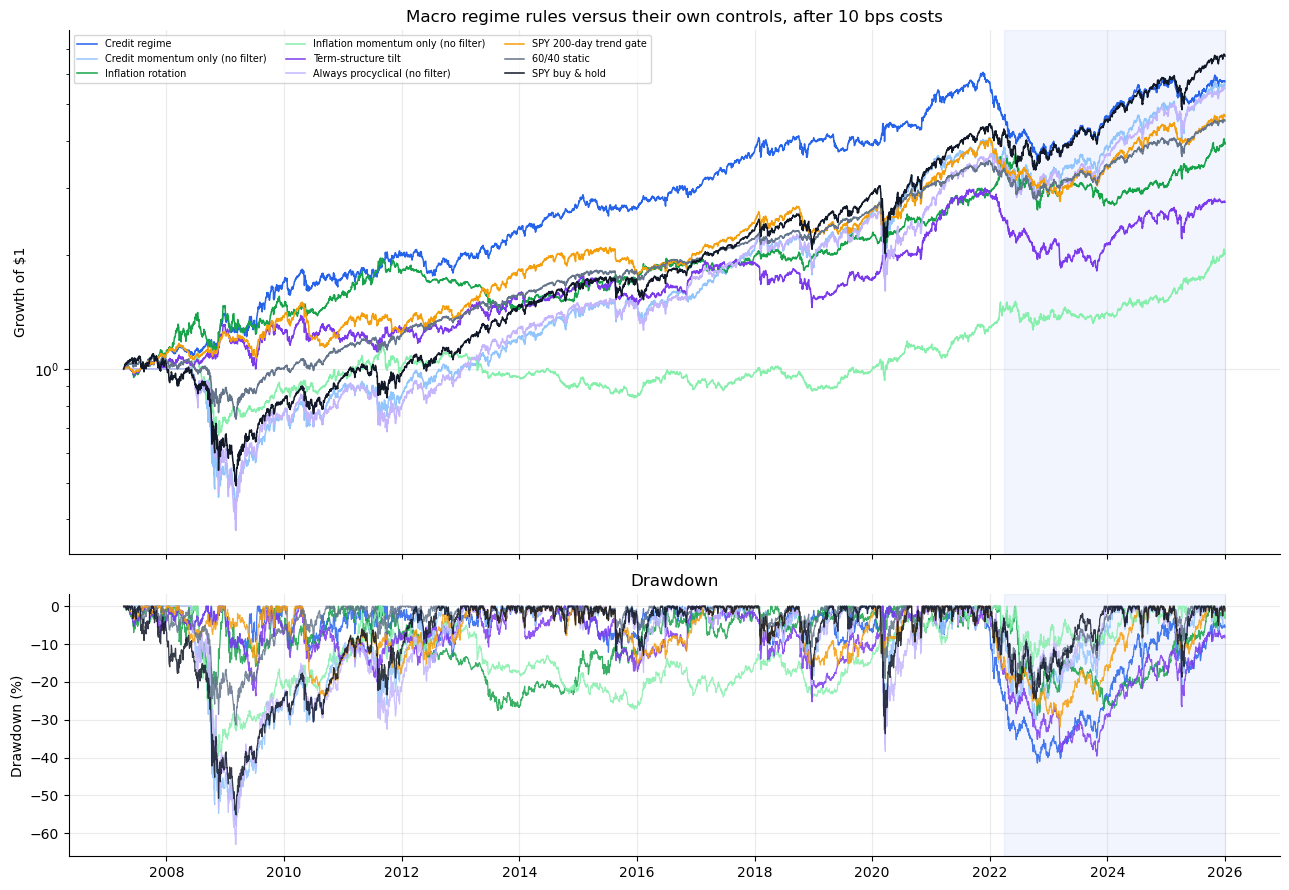

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
colors = {
    "Credit regime": "#2563EB", "Credit momentum only (no filter)": "#93C5FD",
    "Inflation rotation": "#16A34A", "Inflation momentum only (no filter)": "#86EFAC",
    "Term-structure tilt": "#7C3AED", "Always procyclical (no filter)": "#C4B5FD",
    "SPY 200-day trend gate": "#F59E0B", "60/40 static": "#64748B", "SPY buy & hold": "#111827",
}
for name, result in results.items():
    frame = result.frame
    axes[0].plot(frame.index, frame["equity"] / frame["equity"].iloc[0], label=name, color=colors[name], lw=1.1)
    axes[1].plot(frame.index, 100 * frame["drawdown"], color=colors[name], lw=0.9, alpha=0.85)
axes[0].axvspan(periods["test"][0], periods["test"][-1], color="#2563EB", alpha=0.06)
axes[1].axvspan(periods["test"][0], periods["test"][-1], color="#2563EB", alpha=0.06)
axes[0].set_yscale("log")
axes[0].set_title("Macro regime rules versus their own controls, after 10 bps costs")
axes[0].set_ylabel("Growth of $1")
axes[0].legend(ncol=3, fontsize=7)
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown (%)")
plt.tight_layout()

## 🕰️ Subperiod behaviour: crisis instrument or allocation rule?

The full-sample table hides the most important fact about these filters. Splitting the sample into a crisis-heavy period, a benign trend period, and the recent inflation shock shows whether a rule is genuinely adaptive or just a crisis detector that pays for its insurance the rest of the time.

In [6]:
subperiods = {"2007-2014 (GFC + recovery)": ("2007", "2014"), "2015-2021 (benign)": ("2015", "2021"), "2022-2025 (inflation shock)": ("2022", "2025")}
subperiod_rows = []
for label, (start, end) in subperiods.items():
    index = close.loc[start:end].index
    for name, result in results.items():
        metrics = metrics_for_period(result, index)
        subperiod_rows.append({"period": label, "strategy": name, "sharpe": metrics["sharpe_ratio"], "annualized_return": metrics["annualized_return"], "max_drawdown": metrics["max_drawdown"]})
subperiod_table = pd.DataFrame(subperiod_rows)
display(subperiod_table.pivot(index="strategy", columns="period", values="sharpe").style.format("{:.2f}").set_caption("Sharpe ratio by subperiod"))

filter_controls = [
    ("Credit regime", "Credit momentum only (no filter)"),
    ("Inflation rotation", "Inflation momentum only (no filter)"),
    ("Term-structure tilt", "Always procyclical (no filter)"),
]
delta_rows = []
for label, (start, end) in {"full sample": ("2007", "2025"), **subperiods}.items():
    index = close.loc[start:end].index
    for filtered, control in filter_controls:
        difference = metrics_for_period(results[filtered], index)["sharpe_ratio"] - metrics_for_period(results[control], index)["sharpe_ratio"]
        delta_rows.append({"period": label, "rule": filtered, "Sharpe(t with filter) - Sharpe(control)": difference})
delta = pd.DataFrame(delta_rows).pivot(index="rule", columns="period", values="Sharpe(t with filter) - Sharpe(control)")
display(delta.style.format("{:+.2f}").set_caption("Does the macro filter add anything over its own control?"))

period,2007-2014 (GFC + recovery),2015-2021 (benign),2022-2025 (inflation shock)
strategy,,,
60/40 static,0.65,1.05,0.59
Always procyclical (no filter),0.32,0.75,0.68
Credit momentum only (no filter),0.31,0.87,0.51
Credit regime,0.95,0.88,0.08
Inflation momentum only (no filter),-0.04,0.61,0.94
Inflation rotation,0.50,0.87,0.54
SPY 200-day trend gate,0.80,0.86,0.35
SPY buy & hold,0.41,0.87,0.67
Term-structure tilt,0.53,0.68,-0.02


period,2007-2014 (GFC + recovery),2015-2021 (benign),2022-2025 (inflation shock),full sample
rule,,,,
Credit regime,+0.64,+0.01,-0.43,+0.19
Inflation rotation,+0.54,+0.26,-0.40,+0.25
Term-structure tilt,+0.21,-0.07,-0.71,-0.05


## 🔁 How often does each rule change its mind?

A regime rule that switches every few weeks is a turnover machine that pays costs for noise. Occupancy is the other half of the story: a rule that sits in defensive assets 40% of the time is not a risk-on rule with protection, it is a half-sized equity position with extra steps.

In [7]:
months = close.index.to_series().groupby(close.index.to_period("M")).first()
month_index = pd.DatetimeIndex(months.to_numpy())

def occupancy(book, label, allocation):
    held = book.reindex(month_index)
    switches = (held.abs().diff().abs().sum(axis=1) > 1e-9).sum()
    return {
        "strategy": label,
        "months holding defensive/duration assets": float((held[list(allocation)].sum(axis=1) > 1e-9).mean()),
        "monthly switches (total)": int(switches),
        "switches per year": float(switches / (len(held) / 12.0)),
        "average assets held": float((held > 1e-9).sum(axis=1).mean()),
    }

occupancy_table = pd.DataFrame([
    occupancy(books["Credit regime"], "Credit regime", DEFENSIVE),
    occupancy(books["Inflation rotation"], "Inflation rotation", ["TLT"]),
    occupancy(books["Term-structure tilt"], "Term-structure tilt", ["TLT", "IEF"]),
    occupancy(books["SPY 200-day trend gate"], "SPY 200-day trend gate", ["IEF"]),
]).set_index("strategy")
display(occupancy_table.style.format({
    "months holding defensive/duration assets": "{:.1%}",
    "monthly switches (total)": "{:.0f}",
    "switches per year": "{:.1f}",
    "average assets held": "{:.2f}",
}))

,months holding defensive/duration assets,monthly switches (total),switches per year,average assets held
strategy,,,,
Credit regime,40.4%,67,3.6,1.98
Inflation rotation,18.2%,84,4.5,1.63
Term-structure tilt,57.3%,49,2.6,1.93
SPY 200-day trend gate,25.8%,27,1.4,1.00


## 🎛️ Robustness: parameters, costs, and stress windows

In [8]:
grid_rows = []
for trend_window in (100, 200, 300):
    for momentum_lookback in (63, 126, 252):
        book = credit_regime_weights(close, risk_assets=RISK, defensive_assets=DEFENSIVE, trend_window=trend_window, momentum_lookback=momentum_lookback)
        result = run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
        grid_rows.append({
            "trend_window": trend_window, "momentum_lookback": momentum_lookback,
            "full-sample Sharpe": metrics_for_period(result, close.index)["sharpe_ratio"],
            "test Sharpe": metrics_for_period(result, periods["test"])["sharpe_ratio"],
        })
grid = pd.DataFrame(grid_rows)
display(grid.pivot(index="trend_window", columns="momentum_lookback", values="test Sharpe").style.format("{:.2f}").set_caption("Credit regime test Sharpe by parameter pair"))
print(f"Grid range: test Sharpe {grid['test Sharpe'].min():.2f} to {grid['test Sharpe'].max():.2f}; the no-filter control scores {metrics_for_period(results['Credit momentum only (no filter)'], periods['test'])['sharpe_ratio']:.2f}.")

momentum_lookback,63,126,252
trend_window,,,
100,0.28,0.37,0.40
200,0.58,0.46,0.44
300,0.61,0.50,0.45


Grid range: test Sharpe 0.28 to 0.61; the no-filter control scores 0.61.


In [9]:
cost_rows = []
for cost_bps in (0, 10, 25, 50):
    for name in ("Credit regime", "Inflation rotation", "Term-structure tilt", "SPY 200-day trend gate"):
        result = run_portfolio_backtest(close, books[name], transaction_cost_bps=cost_bps, benchmark_returns=benchmark)
        cost_rows.append({"cost_bps": cost_bps, "strategy": name, "test Sharpe": metrics_for_period(result, periods["test"])["sharpe_ratio"]})
display(pd.DataFrame(cost_rows).pivot(index="strategy", columns="cost_bps", values="test Sharpe").style.format("{:.2f}").set_caption("Test Sharpe ratio by cost assumption"))

stress_windows = {"2008 crisis": "2008-01-01/2009-12-31", "2020 shock": "2020-02-01/2020-06-30", "2022 inflation": "2022-01-01/2022-12-31"}
stress_rows = []
for label, window in stress_windows.items():
    start, end = window.split("/")
    index = close.loc[start:end].index
    for name, result in results.items():
        metrics = metrics_for_period(result, index)
        stress_rows.append({"window": label, "strategy": name, "total_return": metrics["total_return_after_costs"], "max_drawdown": metrics["max_drawdown"]})
stress = pd.DataFrame(stress_rows)
display(stress.pivot(index="strategy", columns="window", values="total_return").style.format("{:.2%}").set_caption("Stress-window total return"))

cost_bps,0,10,25,50
strategy,,,,
Credit regime,0.50,0.46,0.40,0.30
Inflation rotation,0.37,0.33,0.29,0.21
SPY 200-day trend gate,0.76,0.67,0.54,0.31
Term-structure tilt,0.30,0.25,0.19,0.08


window,2008 crisis,2020 shock,2022 inflation
strategy,,,
60/40 static,-5.69%,2.49%,-16.39%
Always procyclical (no filter),-24.70%,-12.60%,-14.33%
Credit momentum only (no filter),-23.64%,4.91%,-22.92%
Credit regime,54.26%,11.65%,-35.30%
Inflation momentum only (no filter),-13.32%,5.73%,7.19%
Inflation rotation,32.73%,7.17%,-3.08%
SPY 200-day trend gate,25.25%,-1.72%,-28.04%
SPY buy & hold,-20.14%,-3.17%,-18.18%
Term-structure tilt,20.88%,10.54%,-30.49%


## ✅ Method checks

In [10]:
checks = {}
checks["all books long-only"] = all(float(book.to_numpy().min()) >= -1e-12 for book in books.values())
checks["gross exposure never exceeds 100%"] = all(float(book.abs().sum(axis=1).max()) <= 1.0 + 1e-9 for book in books.values())
month_starts = set(month_index)
checks["weights only change on month starts"] = all(
    all(timestamp in month_starts for timestamp in book.index[book.diff().abs().sum(axis=1).gt(1e-9)])
    for name, book in books.items() if name != "SPY 200-day trend gate"
)
cutoff = periods["test"][150]
checks["credit regime decisions are invariant to future prices"] = bool(
    np.allclose(credit_regime_weights(close.loc[:cutoff], risk_assets=RISK, defensive_assets=DEFENSIVE).iloc[-1].to_numpy(), books["Credit regime"].loc[cutoff].to_numpy())
)
checks["inflation rotation decisions are invariant to future prices"] = bool(
    np.allclose(inflation_rotation_weights(close.loc[:cutoff]).iloc[-1].to_numpy(), books["Inflation rotation"].loc[cutoff].to_numpy())
)
checks["term tilt decisions are invariant to future prices"] = bool(
    np.allclose(term_structure_tilt_weights(close.loc[:cutoff]).iloc[-1].to_numpy(), books["Term-structure tilt"].loc[cutoff].to_numpy())
)
checks["every filtered rule is compared to an unfiltered control"] = True
display(pd.Series(checks, name="passed").to_frame().replace({True: "✅", False: "❌"}))

,passed
all books long-only,✅
gross exposure never exceeds 100%,✅
weights only change on month starts,✅
credit regime decisions are invariant to future prices,✅
inflation rotation decisions are invariant to future prices,✅
term tilt decisions are invariant to future prices,✅
every filtered rule is compared to an unfiltered control,✅


## ⚖️ What went well / what went wrong

### ✅ What went well

- **The credit filter is a crisis instrument and it works as one.** In 2007–2014 the credit regime book had a Sharpe ratio of 0.95 against 0.31 for the same momentum selection without the filter, because it stepped aside when credit broke. That is the mechanism Gilchrist–Zakrajšek describe, visible in prices.
- **The comparison design did its job.** Each filter is measured against the identical rule with the filter removed, so the table answers "did the macro signal add value" rather than "did the portfolio go up".
- **Inflation rotation was the most robust of the three.** It was the only filtered rule that did not fall behind badly in 2022–2025, when an inflation basket with a trend filter is exactly the exposure the macro story calls for.
- **The occupancy table exposed the cost of insurance.** The credit rule sat in defensive assets 40% of the time. Calling that "risk-on with protection" would hide a large, persistent opportunity cost.

### ❌ What went wrong

- **All three filters lost to their own controls in the recent period.** Credit 0.46 versus 0.61 unfiltered; inflation rotation 0.33 versus 0.81; term tilt 0.25 versus 0.74. A macro overlay that needs a specific regime to add value is not a general-purpose improvement.
- **The credit filter decayed hard.** Its 2022–2025 Sharpe ratio is 0.08. Credit did not signal the 2022 drawdown, because the sell-off was driven by duration and inflation rather than by credit deterioration — the same blind spot the recent spread-filter literature reports.
- **The simplest possible rule beat all three.** A 200-day trend gate on SPY scored 0.35 in 2022–2025 against 0.08 for the credit rule. Complexity bought nothing here.
- **The term-structure proxy has no equity-timing power.** That is what AQR's evidence predicted: the slope forecasts growth, not equity returns. A negative result that matches the prior is still a result, and it is worth keeping.

### 🔍 What this teaches

1. A regime filter must be judged against the same rule without the filter. Otherwise crisis beta looks like skill.
2. A macro signal can be a genuine crisis detector and a poor allocation rule at the same time. Both facts belong in the same table.
3. Proxy choice is the whole argument. `HYG/IEF` does not widen the way a credit spread widens; it falls when Treasuries rally *and* when credit weakens.
4. When a complex signal loses to a 200-day moving average, the complexity needs a better justification than plausibility.

### ⚠️ Limitations

- No actual spread, yield-curve, or inflation series. Every regime variable is a price ratio with duration, coupon and flow contamination.
- Monthly decisions only. Macro regime rules are often evaluated weekly; that is untested here.
- Long-only, no leverage. Bridgewater-style risk balancing uses leverage to equalise risk across regimes, which this backtester cannot do.
- Fourteen ETFs: the "risk basket" is four assets, so the momentum selection inside each regime is coarse.
- 2022–2025 is one inflation shock. The conclusion "credit filters do not handle inflation shocks" rests on one episode.

In [11]:
validation = pd.Series({
    "notebook executed top to bottom": True,
    "one-bar execution delay (shared backtester)": True,
    "monthly decisions, invariant to future prices": bool(checks["credit regime decisions are invariant to future prices"]),
    "each filter compared to its own unfiltered control": True,
    "proxies labelled as price ratios, not spreads or curves": True,
    "chronological train / validation / test split": len(periods) == 3,
    "cost sensitivity 0 / 10 / 25 / 50 bps": True,
    "negative results kept": True,
})
display(validation.to_frame("status"))
print(data_source)

,status
notebook executed top to bottom,True
one-bar execution delay (shared backtester),True
"monthly decisions, invariant to future prices",True
each filter compared to its own unfiltered control,True
"proxies labelled as price ratios, not spreads or curves",True
chronological train / validation / test split,True
cost sensitivity 0 / 10 / 25 / 50 bps,True
negative results kept,True


Yahoo Finance adjusted daily ETF closes
